In [1]:
%pip install -U huggingface_hub ollama datasets pandas tqdm -q matplotlib trl


import sys
!{sys.executable} -m pip install --upgrade --no-cache-dir "jinja2>=3.1.6"

from importlib.metadata import version
print(version("jinja2"))

import jinja2
print(jinja2.__version__)

# %conda install -y -c conda-forge compilers
!which gcc
!which clang

import os
os.environ["CC"] = "/opt/conda/bin/gcc"
! /opt/conda/bin/gcc --version

Note: you may need to restart the kernel to use updated packages.
3.1.6
3.1.6
/opt/conda/bin/gcc
gcc (conda-forge gcc 14.2.0-2) 14.2.0
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



In [2]:
import torch
from datasets import load_dataset
from trl import DPOConfig, DPOTrainer

use_cuda = torch.cuda.is_available()
print(f"GPU available: {torch.cuda.is_available()}")

!nvidia-smi

GPU available: True
Wed Nov 25 01:23:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.108                Driver Version: 581.83         CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce GTX 1050        On  |   00000000:01:00.0  On |                  N/A |
| N/A   38C    P5            N/A  / 5001W |    2935MiB /   3072MiB |      7%      Default |
|                                         |                        |                  N/A |
+---------------------------

In [14]:
from huggingface_hub import notebook_login

notebook_login()

In [15]:
# https://huggingface.co/learn/cookbook/en/llm_judge

import re
import torch
import pandas as pd
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import InferenceClient, notebook_login

def generate(model, messages, max_new_tokens=100):
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    inputs = tokenizer(text, return_tensors="pt").to(device)

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True)

In [17]:

BASE = "HuggingFaceTB/SmolLM2-135M-Instruct"
TUNED = f"./{BASE}_dpo/checkpoint-100/"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(BASE)
base_model = AutoModelForCausalLM.from_pretrained(BASE).to(device).eval()
tuned_model = AutoModelForCausalLM.from_pretrained(TUNED).to(device).eval()


# https://huggingface.co/datasets/trl-lib/ultrafeedback_binarized
data = load_dataset("trl-lib/ultrafeedback_binarized", split="train")
examples = data.shuffle(seed=123).select(range(10))


analyse_dir = os.path.join(f"./{BASE}_dpo", "analyse")
os.makedirs(analyse_dir, exist_ok=True)
comparaison_file = os.path.join(analyse_dir, "comparaison_base_dpo.csv")


pd.DataFrame(columns=[
    "id", "prompt", "base_response", "dpo_response"
]).to_csv(comparaison_file, index=False, encoding="utf-8-sig")

for i, ex in enumerate(examples):
    prompt_messages = ex["chosen"][:-1]

    row = {
        "id": i,
        "prompt": str(prompt_messages),
        "base_response": generate(base_model, prompt_messages),
        "dpo_response": generate(tuned_model, prompt_messages),
    }

    pd.DataFrame([row]).to_csv(
        comparaison_file,
        mode="a",
        header=False,
        index=False,
        encoding="utf-8-sig",
    )

    print(f"Itération {i + 1}/{len(examples)} enregistrée")



for i, ex in enumerate(examples):
    prompt_messages = ex["chosen"][:-1]

    rows.append({
        "id": i,
        "prompt": str(prompt_messages),
        "base_response": generate(base_model, prompt_messages),
        "dpo_response": generate(tuned_model, prompt_messages),
    })


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Itération 1/10 enregistrée
Itération 2/10 enregistrée
Itération 3/10 enregistrée
Itération 4/10 enregistrée
Itération 5/10 enregistrée
Itération 6/10 enregistrée
Itération 7/10 enregistrée
Itération 8/10 enregistrée
Itération 9/10 enregistrée
Itération 10/10 enregistrée


NameError: name 'rows' is not defined

In [ ]:
import requests

r = requests.get("http://ollama_GPU:11434/api/tags", timeout=10)
print(r.status_code, r.text)



In [18]:
import re
import ollama

client = ollama.Client(host="http://ollama_GPU:11434")


JUDGE_MODEL = "llama3.1:latest"

def evaluate(question, answer):
    result = client.chat(
        model=JUDGE_MODEL,
        messages=[
            {
                "role": "system",
                "content": (
                    "You are evaluating an assistant’s response. "
                    "Rate it from 1 to 4: 1 = off-topic, 2 = partially relevant, "
                    "3 = helpful but could be improved, 4 = accurate and complete. "
                    "Give a brief justification, then write exactly "
                    "'Total rating: N’, where N is an integer from 1 to 4."
                ),
            },
            {
                "role": "user",
                "content": (
                    f"Question :\n{question}\n\n"
                    f"Réponse à évaluer :\n{answer}"
                ),
            },
        ],
    )

    text = result.message.content
    match = re.search(r"Total rating:\s*([1-4])", text, re.IGNORECASE)
    score = int(match.group(1)) if match else None

    return text, score


print ("Ollama connect")


Ollama connect


In [24]:

import os
import pandas as pd


judgee_file = os.path.join(analyse_dir, "comparaison_judgee.csv")
df = pd.read_csv(comparaison_file)

if os.path.exists(judgee_file):
    saved = pd.read_csv(judgee_file)
    if len(saved) == len(df):
        df = saved

columns = [
    "base_judge",
    "base_judge_score",
    "dpo_judge",
    "dpo_judge_score",
]

# Ajoute les colonnes absentes
for col in columns:
    if col not in df.columns:
        df[col] = pd.NA

def save_progress():
    df.to_csv(judgee_file, index=False, encoding="utf-8-sig")

for i, row in df.iterrows():
    if pd.isna(df.at[i, "base_judge_score"]):
        result, score = evaluate(row["prompt"], row["base_response"])
        df.at[i, "base_judge"] = result
        df.at[i, "base_judge_score"] = score
        save_progress()
        print(f"Ligne {i + 1}/{len(df)} — évaluation base enregistrée")

    if pd.isna(df.at[i, "dpo_judge_score"]):
        result, score = evaluate(row["prompt"], row["dpo_response"])
        df.at[i, "dpo_judge"] = result
        df.at[i, "dpo_judge_score"] = score
        save_progress()
        print(f"Ligne {i + 1}/{len(df)} — évaluation DPO enregistrée")

print(f"\nRésultats enregistrés dans {judgee_file}")
print("Moyenne base :", pd.to_numeric(df["base_judge_score"], errors="coerce").mean())
print("Moyenne DPO  :", pd.to_numeric(df["dpo_judge_score"], errors="coerce").mean())




Résultats enregistrés dans ./HuggingFaceTB/SmolLM2-135M-Instruct_dpo/analyse/comparaison_judgee.csv
Moyenne base : 2.9
Moyenne DPO  : 3.1


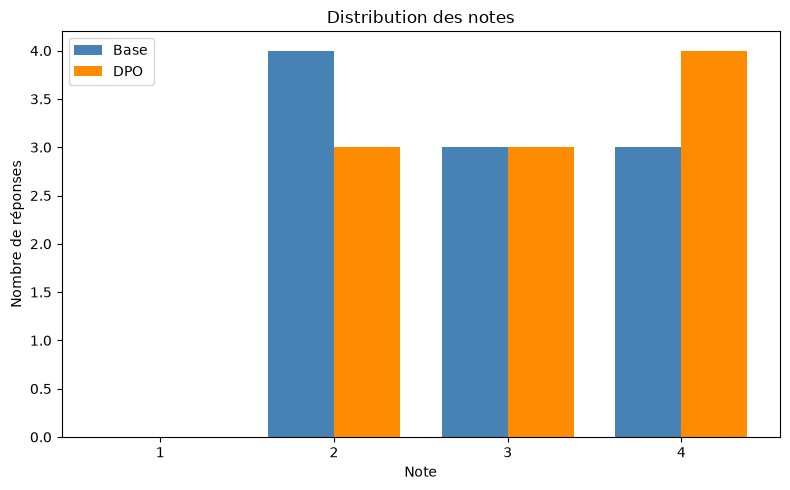

In [27]:
import matplotlib.pyplot as plt

base = pd.to_numeric(df["base_judge_score"], errors="coerce").dropna()
dpo = pd.to_numeric(df["dpo_judge_score"], errors="coerce").dropna()

#  1 = off-topic, 2 = partially relevant, 3 = helpful but could be improved, 4 = accurate and complete.
scores = [1, 2, 3, 4]
base_counts = base.value_counts().reindex(scores, fill_value=0)
dpo_counts = dpo.value_counts().reindex(scores, fill_value=0)

x = range(len(scores))
width = 0.38

plt.figure(figsize=(8, 5))
plt.bar(
    [i - width / 2 for i in x],
    base_counts,
    width,
    label="Base",
    color="steelblue",
)
plt.bar(
    [i + width / 2 for i in x],
    dpo_counts,
    width,
    label="DPO",
    color="darkorange",
)

plt.xticks(list(x), scores)
plt.xlabel("Note")
plt.ylabel("Nombre de réponses")
plt.title("Distribution des notes")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(analyse_dir, "distribution_notes.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/workspace/analyse/comparaison_reponses.png'

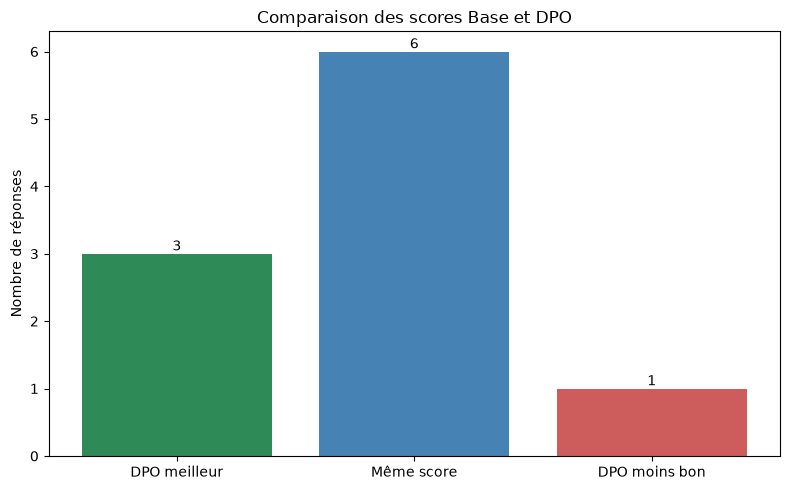

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

comparaison = pd.DataFrame({
    "base": pd.to_numeric(df["base_judge_score"], errors="coerce"),
    "dpo": pd.to_numeric(df["dpo_judge_score"], errors="coerce"),
}).dropna()

amelioration = (comparaison["dpo"] > comparaison["base"]).sum()
identique = (comparaison["dpo"] == comparaison["base"]).sum()
baisse = (comparaison["dpo"] < comparaison["base"]).sum()

labels = ["DPO meilleur", "Même score", "DPO moins bon"]
valeurs = [amelioration, identique, baisse]
couleurs = ["seagreen", "steelblue", "indianred"]

plt.figure(figsize=(8, 5))
barres = plt.bar(labels, valeurs, color=couleurs)

plt.ylabel("Nombre de réponses")
plt.title("Comparaison des scores Base et DPO")

for barre, valeur in zip(barres, valeurs):
    plt.text(
        barre.get_x() + barre.get_width() / 2,
        barre.get_height(),
        str(valeur),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.savefig(
    os.path.join(analyse_dir, "comparaison_reponses.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()



In [ ]:
print("Done")